# 01 · Análisis exploratorio (EDA): Airbnb en Madrid

Este notebook recorre el análisis exploratorio del proyecto. **No repite la limpieza**: lee el dataset
procesado (`data/processed/listings_limpio.parquet`) y los resultados (`reports/findings.json`) que genera
`python run_pipeline.py`, y llama a las mismas funciones de `src/` que el pipeline.

Se genera desde `notebooks/fuentes_py/01_eda.py` con `python scripts/ejecutar_notebooks.py`.

In [1]:
import sys
from pathlib import Path

sys.dont_write_bytecode = True
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import json

import matplotlib.pyplot as plt
import pandas as pd

from src import analisis, carga, config, formato as fmt, visualizacion as viz

%matplotlib inline
viz.configurar_estilo()
pd.set_option("display.max_columns", 30)

df = pd.read_parquet(config.RUTA_PARQUET)
with open(config.RUTA_FINDINGS, encoding="utf-8") as f:
    findings = json.load(f)
with open(config.RUTA_CALIDAD, encoding="utf-8") as f:
    calidad = json.load(f)
print(f"Dataset procesado: {fmt.n0(df.shape[0])} filas × {fmt.n0(df.shape[1])} columnas")

Dataset procesado: 23.109 filas × 109 columnas


## 1. Datos y requisitos mínimos

Snapshot, licencia verificada y comprobación de los umbrales del dataset (calculados por `src/calidad.py`
sobre el fichero original).

In [2]:
meta, dataset = findings["meta"], findings["dataset"]
print("Snapshot (fecha de la URL):", meta["fecha_snapshot_url"])
print("Fechas de scrape (last_scraped):", meta["last_scraped_min"][:10], "→", meta["last_scraped_max"][:10])
print("Licencia:", dataset["licencia"]["nombre"], "| verificada en la página:", dataset["licencia"]["verificada_en_pagina"])
print("Filas y columnas originales:", fmt.n0(dataset["filas_raw"]), "×", dataset["columnas_raw"])
pd.Series(dataset["tipos_raw"], name="columnas por tipo lógico").to_frame()

Snapshot (fecha de la URL): 2026-09-17
Fechas de scrape (last_scraped): 2026-09-19 → 2026-09-22
Licencia: Creative Commons Attribution 4.0 International (CC BY 4.0) | verificada en la página: True
Filas y columnas originales: 23.109 × 90


,columnas por tipo lógico
booleano,4
categorico,4
fecha,6
geoespacial,2
identificador,10
numerico,54
texto,10


In [3]:
pd.DataFrame(dataset["requisitos"]["tipos_presentes"], index=["presente"]).T

,presente
numerico,True
categorico,True
fecha,True
texto,True
geoespacial,True


## 2. Calidad de datos antes y después de limpiar

El detalle de cada regla (conversiones, columnas eliminadas con su motivo, política de nulos y filas afectadas)
está en `reports/calidad_datos.json`.

In [4]:
resumen = pd.DataFrame({
    "antes": {k: calidad["antes"][k] for k in ("filas", "columnas", "nulos_total", "pct_nulos_total", "columnas_con_nulos")},
    "después": {k: calidad["despues"][k] for k in ("filas", "columnas", "nulos_total", "pct_nulos_total", "columnas_con_nulos")},
})
resumen

,antes,después
filas,23109.000000,23109.000000
columnas,90.000000,109.000000
nulos_total,425829.000000,114173.000000
pct_nulos_total,20.474418,4.532687
columnas_con_nulos,46.000000,31.000000


In [5]:
pd.Series(calidad["reglas"], name="filas afectadas").to_frame()

,filas afectadas
precio_nulo_o_no_positivo (precio_valido=False),4324
"outlier_precio (flag, no se borra)",609
minimum_nights > 365 (flag),8
minimum_nights >= 30 (flag larga estancia),3151
coordenadas fuera del bbox o nulas (excluidas de mapa y distancia),0
duplicados por id (eliminados),0
bedrooms imputado con mediana por grupo,12
beds imputado con mediana por grupo,574


In [6]:
pd.DataFrame(calidad["politica_nulos"])[["columna", "nulos", "decision"]].head(20)

,columna,nulos,decision
0,host_location,7864,conservar NaN; license se resume en licencia_tipo
1,bathrooms,19,conservar NaN
2,bedrooms,0,"imputar mediana por (room_type, accommodates);..."
3,beds,0,"imputar mediana por (room_type, accommodates);..."
4,price,4324,conservar NaN; precio_valido=False
5,price_quote_checkin_date,3568,conservar NaN
6,price_quote_checkout_date,3568,conservar NaN
7,price_quote_total_price,4936,conservar NaN
8,price_quote_price_per_night,4936,conservar NaN
9,minimum_nights,1729,conservar NaN


In [7]:
pd.Series(calidad["columnas_eliminadas"], name="motivo").to_frame()

,motivo
neighborhood_overview,100 % nulas en este snapshot
host_since,100 % nulas en este snapshot
host_response_time,100 % nulas en este snapshot
host_response_rate,100 % nulas en este snapshot
host_acceptance_rate,100 % nulas en este snapshot
host_thumbnail_url,100 % nulas en este snapshot
host_neighbourhood,100 % nulas en este snapshot
host_total_listings_count,100 % nulas en este snapshot
host_verifications,100 % nulas en este snapshot
neighbourhood,100 % nulas en este snapshot


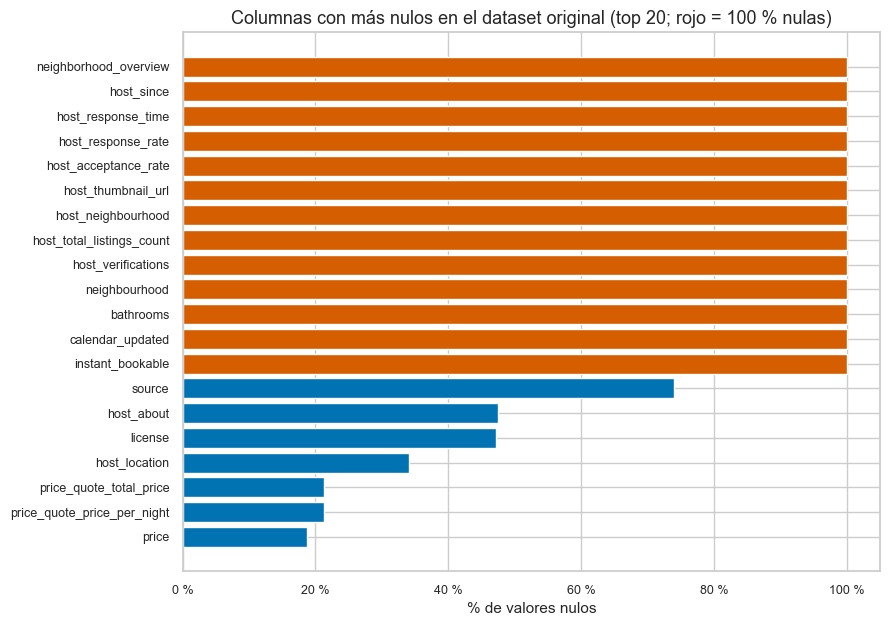

In [8]:
perfil_antes = {"nulos_por_columna_pct": (carga.leer_listings().isna().mean() * 100).to_dict()}
viz.fig_calidad_nulos(perfil_antes);

## 3. Distribución del precio

Se describen solo los anuncios con precio publicado (`precio_valido`). Los precios nulos se concentran en
anuncios sin disponibilidad y no se imputan.

In [9]:
con_precio = df[df["precio_valido"]]
desc = pd.DataFrame({
    "precio": analisis.descriptivos(con_precio["price"]),
    "precio sin outliers": analisis.descriptivos(con_precio.loc[~con_precio["es_outlier_precio"], "price"]),
    "ln(precio)": analisis.descriptivos(con_precio["log_precio"]),
})
# Comprobación: el notebook reproduce las mismas cifras que findings.json.
assert abs(desc.loc["mediana", "precio"] - findings["descriptivo"]["precio"]["mediana"]) < 1e-9
assert abs(desc.loc["asimetria", "precio"] - findings["descriptivo"]["precio"]["asimetria"]) < 1e-9
desc.round(2)

,precio,precio sin outliers,ln(precio)
n,18785.00,18176.00,18785.00
media,208.63,178.61,4.98
mediana,151.00,151.00,5.02
std,543.63,121.25,0.75
q1,95.45,98.00,4.56
q3,224.50,220.92,5.41
iqr,129.05,122.92,0.86
min,9.13,26.47,2.21
max,36883.00,808.00,10.52
p5,38.52,43.77,3.65


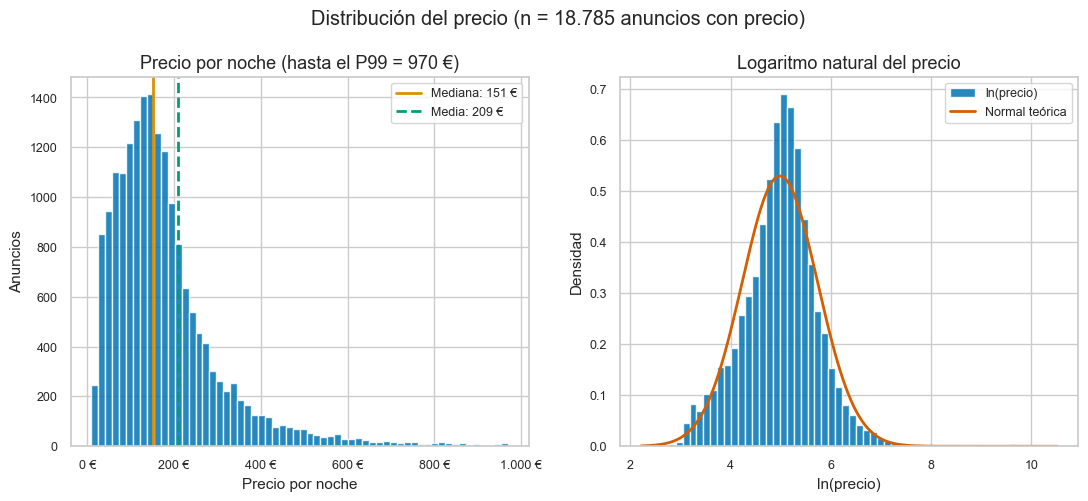

In [10]:
viz.fig_distribucion_precio(df);

In [11]:
print("Vallas IQR sobre ln(precio):", fmt.eur2(findings["limpieza"]["outliers"]["valla_inf"]), "y",
      fmt.eur2(findings["limpieza"]["outliers"]["valla_sup"]))
print("Outliers marcados (no borrados):", fmt.n0(findings["limpieza"]["outliers"]["n_total"]))

Vallas IQR sobre ln(precio): 26,46 € y 809,80 €
Outliers marcados (no borrados): 609


## 4. Otras variables clave

In [12]:
pd.DataFrame({c: analisis.descriptivos(df[c]) for c in
              ["accommodates", "minimum_nights", "availability_365", "number_of_reviews", "review_scores_rating"]}).round(2)

,accommodates,minimum_nights,availability_365,number_of_reviews,review_scores_rating
n,23109.00,21380.00,23109.00,23109.00,19294.00
media,3.26,8.87,159.55,65.98,4.64
mediana,3.00,2.00,151.00,22.00,4.75
std,1.93,26.24,136.26,111.76,0.48
q1,2.00,1.00,1.00,2.00,4.55
q3,4.00,5.00,298.00,80.00,4.91
iqr,2.00,4.00,297.00,78.00,0.36
min,1.00,1.00,0.00,0.00,0.00
max,16.00,1125.00,365.00,1600.00,5.00
p5,1.00,1.00,0.00,0.00,4.00


## 5. Precio por tipo de habitación, distrito, barrio y capacidad

In [13]:
pd.DataFrame(findings["descriptivo"]["por_tipo"]).round(2)

,grupo,n,mediana,media,q1,q3
0,Alojamiento entero,13561,173.63,234.55,127.5,247.95
1,Habitación de hotel,29,162.00,174.34,127.0,201.00
2,Habitación privada,5059,74.00,142.95,47.0,128.00
3,Habitación compartida,136,27.00,74.81,24.0,40.00


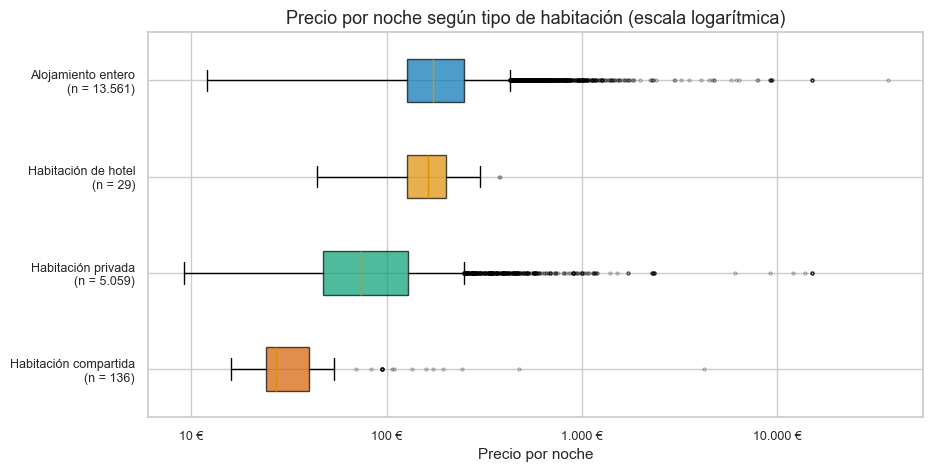

In [14]:
viz.fig_precio_por_tipo(df);

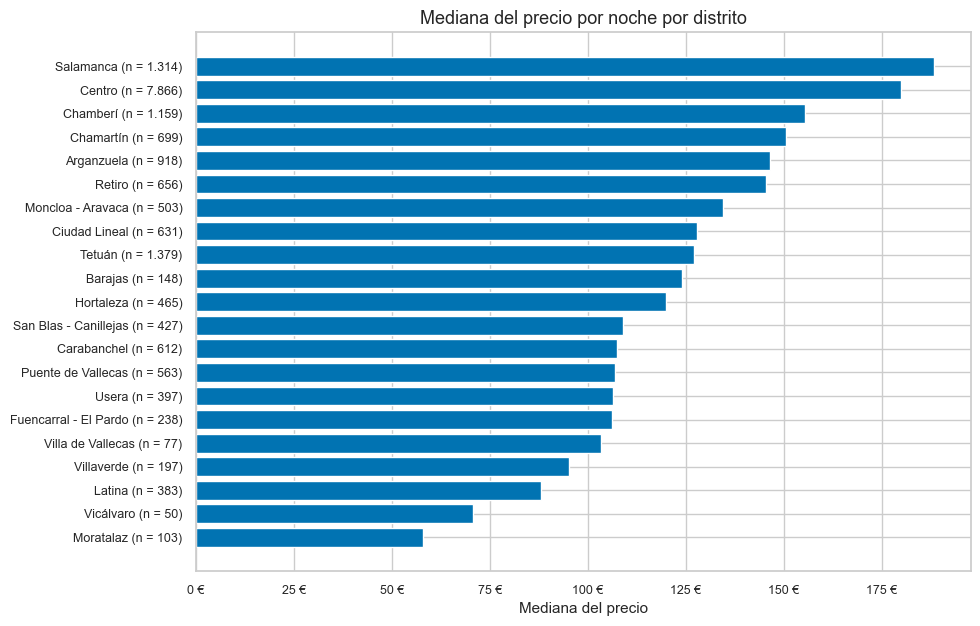

In [15]:
viz.fig_precio_por_distrito(findings);

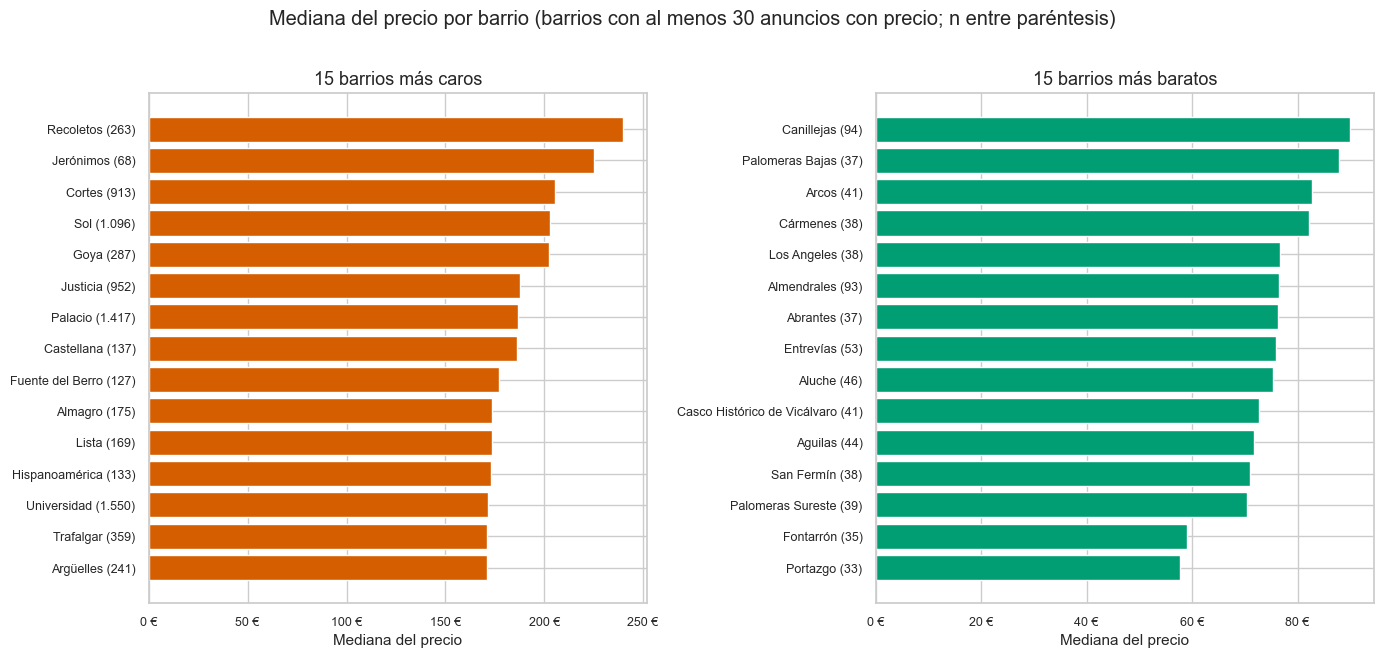

In [16]:
viz.fig_precio_por_barrio(df, config.MIN_N_GRUPO);

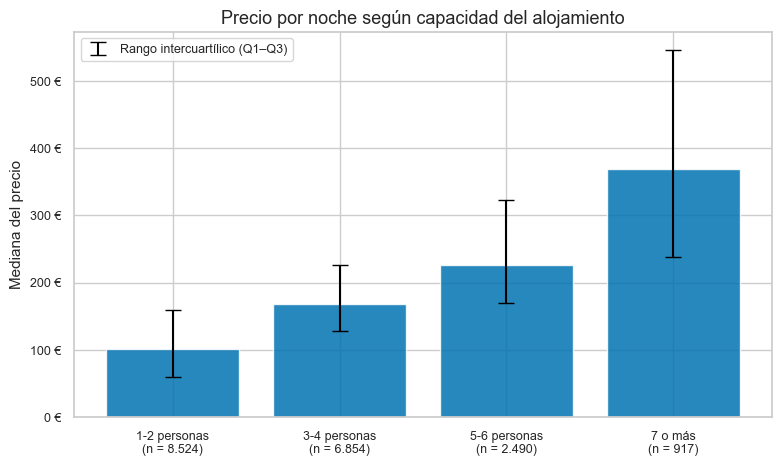

In [17]:
viz.fig_precio_por_capacidad(findings);

## 6. Composición de anfitriones

In [18]:
pd.Series(findings["descriptivo"]["hosts"]).drop(["segmentos", "segmentos_pct"]).to_frame("valor")

,valor
n_anuncios,23109
n_hosts,8704
anuncios_por_host_media,2.654986
anuncios_por_host_mediana,1.0
anuncios_por_host_max,469
pct_hosts_un_anuncio,70.301011
pct_anuncios_multianuncio,73.521139
pct_anuncios_superhost,23.813233
pct_hosts_superhost,27.079504
pct_anuncios_hosts_6_o_mas,50.028128


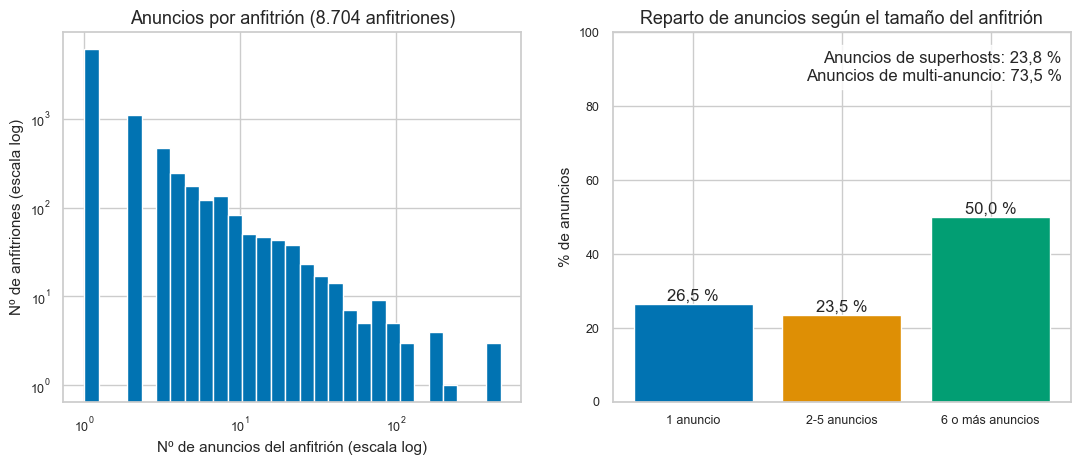

In [19]:
viz.fig_composicion_hosts(df, findings);

## 7. Mapas de densidad y de precio

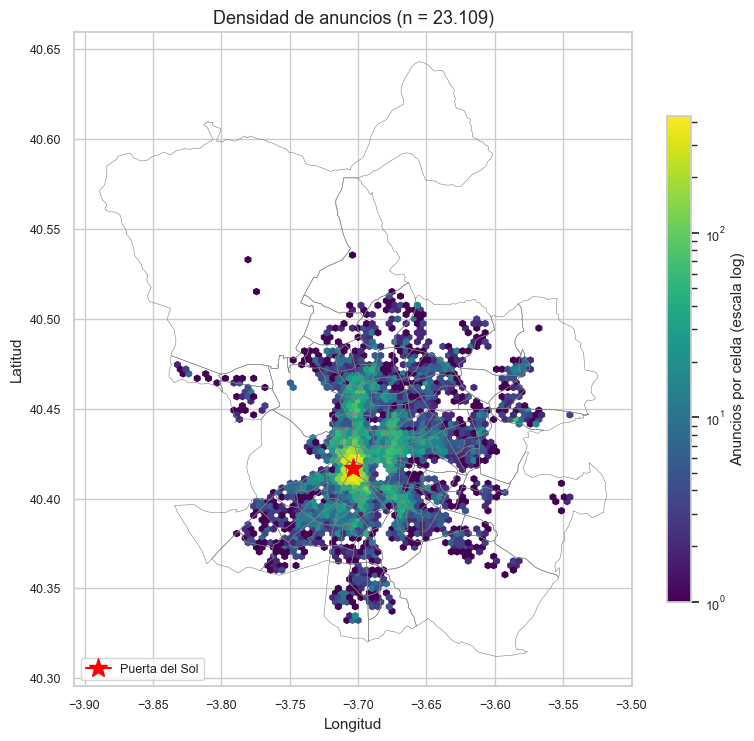

In [20]:
geojson = carga.leer_geojson()
ciudad = config.CIUDADES[config.CIUDAD_POR_DEFECTO]
viz.fig_mapa_densidad(df, geojson, ciudad.centro, ciudad.centro_nombre);

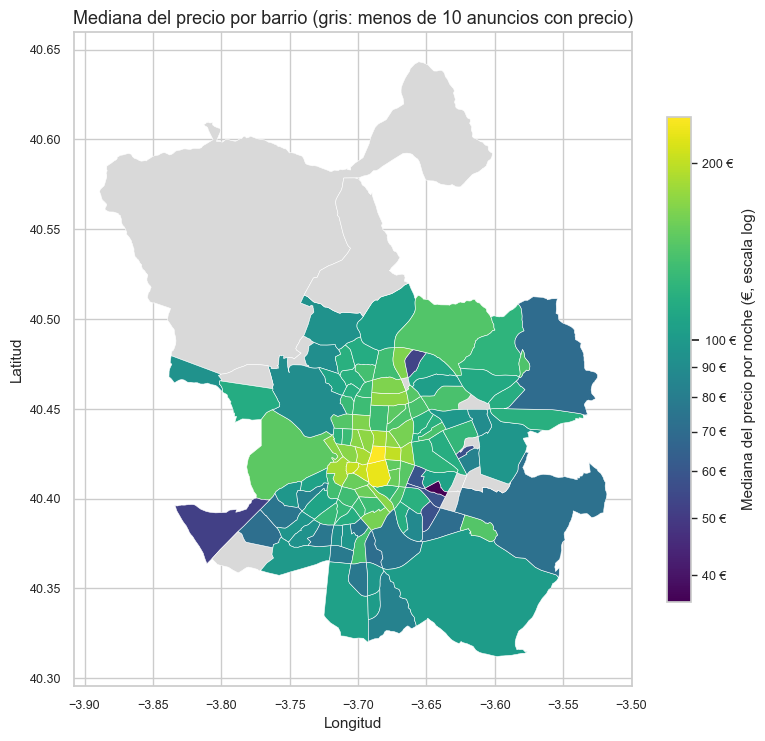

In [21]:
viz.fig_mapa_precio_barrio(df, geojson, config.MIN_N_BARRIO_MAPA);

## 8. Ocupación e ingresos estimados

`365 − availability_365` **no es ocupación real**; se compara con la estimación de Inside Airbnb.

In [22]:
pd.Series(findings["descriptivo"]["ocupacion_ingresos"]).to_frame("valor").round(3)

,valor
n_activos_con_precio,18757.000
ocupacion_estimada_media,48.630
ocupacion_estimada_mediana,39.726
ocupacion_inside_airbnb_media,31.564
ocupacion_inside_airbnb_mediana,26.301
ingresos_propios_mediana,19503.440
ingresos_inside_airbnb_mediana,12432.000
cociente_medianas,1.569
spearman_propio_vs_inside,0.467
spearman_p,0.000


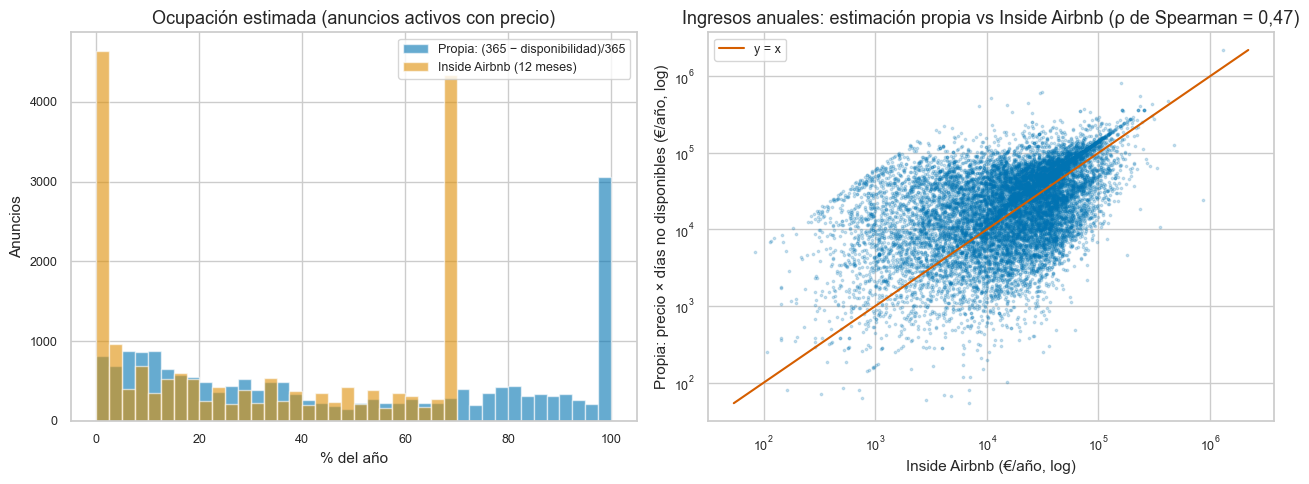

In [23]:
viz.fig_ocupacion_ingresos(df, findings);

## 9. Amenities

In [24]:
pd.DataFrame(findings["descriptivo"]["amenities"]).round(1)

,amenity,nombre,prevalencia_pct,mediana_con,mediana_sin,prima_pct
0,tiene_wifi,Wifi,96.8,151.5,133.7,13.3
1,tiene_cocina,Cocina,88.7,154.9,123.2,25.7
2,tiene_lavadora,Lavadora,83.4,155.4,132.6,17.2
3,tiene_calefaccion,Calefacción,82.0,157.8,120.0,31.5
4,tiene_tv,TV,78.1,158.0,115.0,37.4
5,tiene_aire_acondicionado,Aire acondicionado,68.1,165.0,109.5,50.7
6,tiene_espacio_trabajo,Espacio de trabajo,47.4,148.0,154.2,-4.0
7,tiene_ascensor,Ascensor,46.0,171.0,137.0,24.8
8,tiene_parking_cualquiera,Parking (cualquiera),37.6,148.0,153.0,-3.3
9,llegada_autonoma,Llegada autónoma,31.8,169.4,140.0,21.0


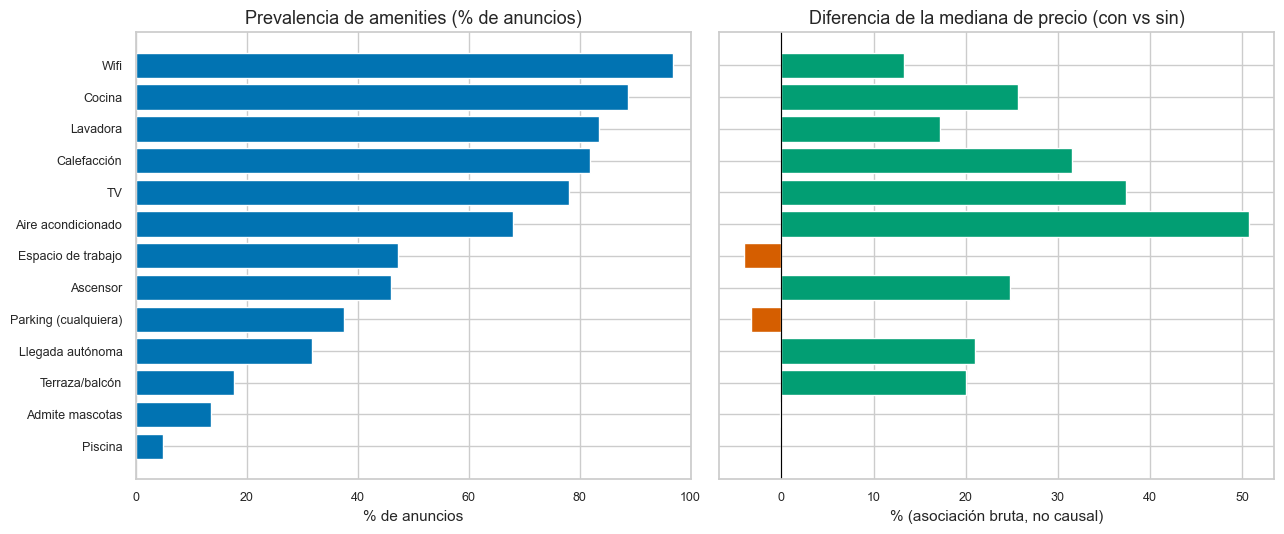

In [25]:
viz.fig_amenities(findings);

## 10. Correlaciones (Pearson y Spearman)

Spearman es más adecuado con un precio tan asimétrico; Pearson sobre el precio original queda dominado por los
valores extremos.

In [26]:
pd.DataFrame(findings["descriptivo"]["correlaciones"]["con_precio"]).round(3)

,variable,spearman,pearson_log,pearson
0,accommodates,0.597,0.555,0.169
1,beds,0.489,0.259,0.083
2,bedrooms,0.398,0.331,0.118
3,distancia_centro_km,-0.310,-0.243,-0.070
4,n_amenities,0.232,0.212,-0.004
5,bathrooms,0.199,0.135,0.081
6,minimum_nights,-0.191,-0.230,-0.056
7,number_of_reviews,0.137,0.061,-0.017
8,antiguedad_host_anios,0.122,0.111,-0.001
9,reviews_per_month,0.119,0.031,-0.014


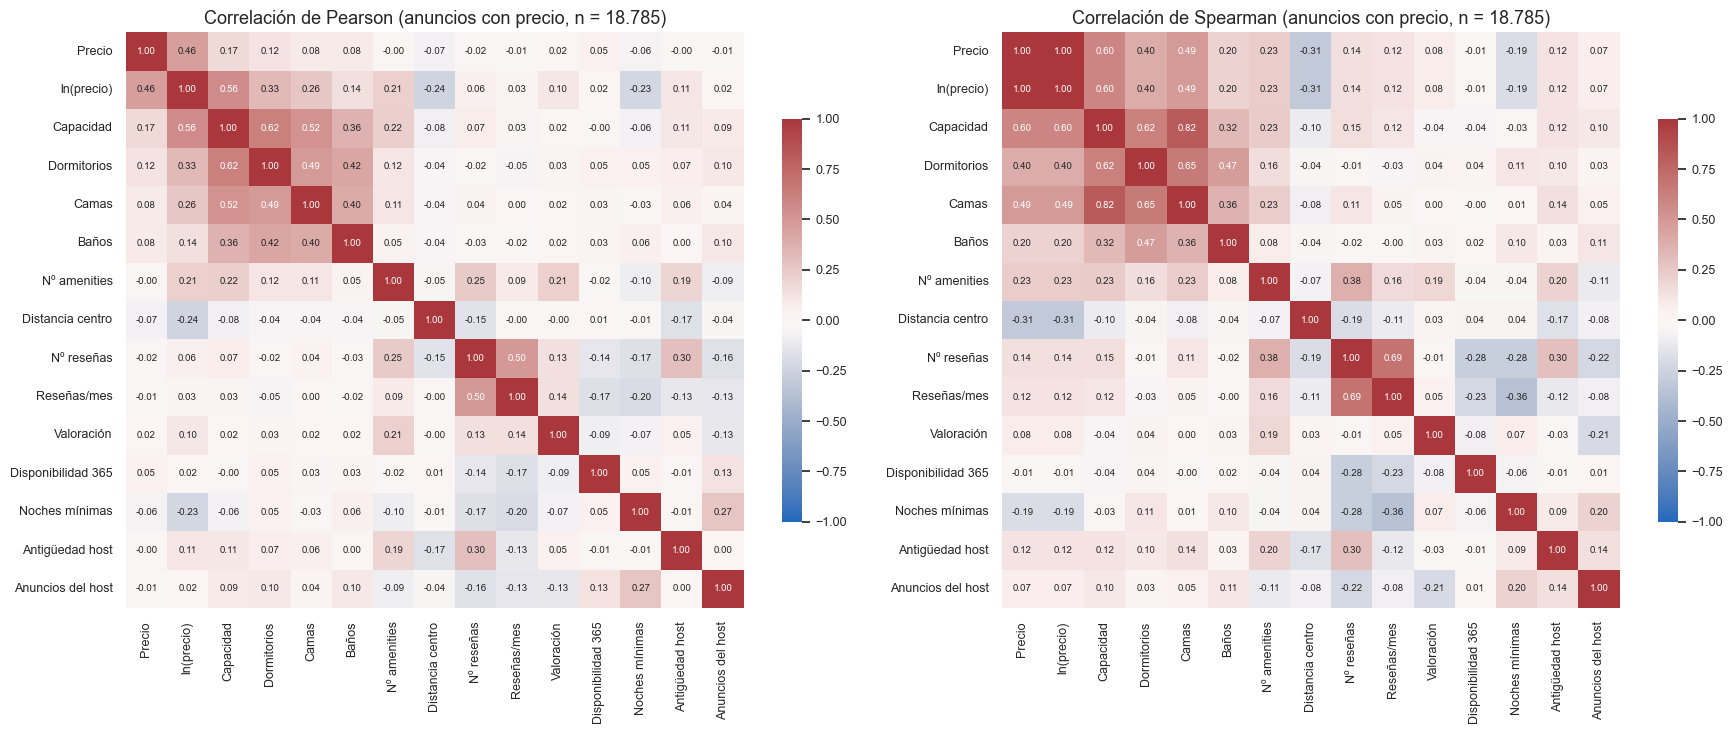

In [27]:
viz.fig_correlaciones(findings);

## Conclusión del EDA

El precio es muy asimétrico, depende sobre todo del tipo de alojamiento, la capacidad y la ubicación, y la oferta
está muy concentrada en anfitriones con varios anuncios. Estas hipótesis se contrastan formalmente en
`02_analisis_estadistico.ipynb`. Las cifras y su interpretación completa están en `reports/informe.md`.